In [ ]:
from google.colab import userdata
import os

# Change this api for groq
os.environ["GROQ_API_KEY"] = "ENTER YOUR API KEY"

In [2]:
!pip install groq datasets transformers pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.3/138.3 kB 10.2 MB/s eta 0:00:00


In [3]:
!wget https://okvqa.allenai.org/static/data/mscoco_train2014_annotations.json
!wget https://okvqa.allenai.org/static/data/OpenEnded_mscoco_train2014_questions.json

--2026-02-26 06:14:36--  https://okvqa.allenai.org/static/data/mscoco_train2014_annotations.json
Resolving okvqa.allenai.org (okvqa.allenai.org)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to okvqa.allenai.org (okvqa.allenai.org)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9286077 (8.9M) [application/json]
Saving to: ‘mscoco_train2014_annotations.json’

mscoco_train2014_an 100%[===================>]   8.86M  --.-KB/s    in 0.07s   

2026-02-26 06:14:37 (129 MB/s) - ‘mscoco_train2014_annotations.json’ saved [9286077/9286077]

--2026-02-26 06:14:37--  https://okvqa.allenai.org/static/data/OpenEnded_mscoco_train2014_questions.json
Resolving okvqa.allenai.org (okvqa.allenai.org)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to okvqa.allenai.org (okvqa.allenai.org)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 931923 (910K) [application/json]
Saving to: ‘

In [4]:
import json

with open("OpenEnded_mscoco_train2014_questions.json") as f:
    questions_data = json.load(f)

with open("mscoco_train2014_annotations.json") as f:
    annotations_data = json.load(f)

questions = questions_data["questions"]
annotations = annotations_data["annotations"]

print("Total questions:", len(questions))

Total questions: 9009


In [5]:
id_to_answers = {}

for ann in annotations:
    qid = ann["question_id"]
    id_to_answers[qid] = ann["answers"]

dataset = []

for q in questions:
    qid = q["question_id"]

    if qid in id_to_answers:
        dataset.append({
            "question_id": qid,
            "image_id": q["image_id"],
            "question": q["question"],
            "answers": id_to_answers[qid]
        })

print("Merged samples:", len(dataset))

Merged samples: 9009


In [6]:
dataset[:5]

[{'question_id': 516065,
  'image_id': 51606,
  'question': 'What is the hairstyle of the blond called?',
  'answers': [{'answer_id': 1,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 2,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 3,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 4,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 5,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 6,
    'raw_answer': 'pony tail',
    'answer_confidence': 'yes',
    'answer': 'poni tail'},
   {'answer_id': 7,
    'raw_answer': 'braid',
    'answer_confidence': 'yes',
    'answer': 'braid'},
   {'answer_id': 8,
    'raw_answer': 'braid',
    'answer_confidence': 'yes',
    'answer': 'braid'},
   {'answer

In [7]:
def get_coco_image_url(image_id):
    return f"http://images.cocodataset.org/train2014/COCO_train2014_{image_id:012d}.jpg"

In [8]:
sample = dataset[0]

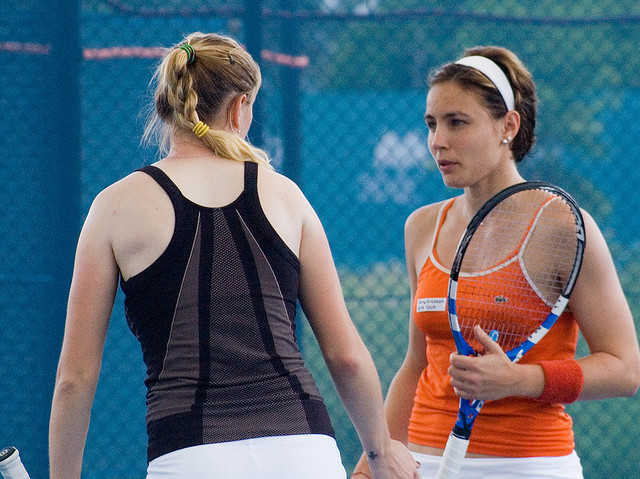

In [9]:
from PIL import Image
import requests
from io import BytesIO

url = get_coco_image_url(sample["image_id"])
response = requests.get(url, stream=True)
image = Image.open(response.raw).convert("RGB")

image

In [10]:
import re

def normalize_answer(ans):
    ans = ans.lower().strip()
    ans = re.sub(r"[^\w\s]", "", ans)  # remove punctuation
    ans = re.sub(r"\s+", " ", ans)     # remove extra spaces
    return ans

In [11]:
from collections import Counter

def get_majority_answer(answers):
    answer_list = [normalize_answer(a["answer"]) for a in answers]
    most_common = Counter(answer_list).most_common(1)[0][0]
    return most_common

In [12]:
clean_dataset = []

for sample in dataset:

    majority_answer = get_majority_answer(sample["answers"])

    clean_dataset.append({
        "question_id": sample["question_id"],
        "image_id": sample["image_id"],
        "question": sample["question"],
        "answer": majority_answer
    })

In [13]:
clean_dataset[0]

{'question_id': 516065,
 'image_id': 51606,
 'question': 'What is the hairstyle of the blond called?',
 'answer': 'poni tail'}

In [14]:
from collections import Counter

answer_counts = Counter([sample["answer"] for sample in clean_dataset])

print("Total unique answers:", len(answer_counts))

Total unique answers: 4085


In [15]:
len(clean_dataset)

9009

In [16]:
top_k = 1000
most_common_answers = set([ans for ans, _ in answer_counts.most_common(top_k)])

filtered_dataset = [
    sample for sample in clean_dataset
    if sample["answer"] in most_common_answers
]

In [17]:
print("Filtered dataset size:", len(filtered_dataset))

Filtered dataset size: 5042


In [18]:
import json

with open("okvqa_clean_dataset.json", "w") as f:
    json.dump(filtered_dataset, f, indent=2)

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [20]:
import os
# Change this location to drive
CACHE_DIR = "/content/drive/MyDrive/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
import json

with open("okvqa_clean_dataset.json", "r") as f:
    clean_dataset = json.load(f)

print("Total samples:", len(clean_dataset))

Total samples: 5042


In [23]:
def get_coco_image_url(image_id):
    return f"http://images.cocodataset.org/train2014/COCO_train2014_{image_id:012d}.jpg"

In [24]:
from transformers import BlipProcessor, BlipForConditionalGeneration
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
caption_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

caption_model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

...

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-11): 12 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (projection): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        )
      )
    )
    (post_layernorm): LayerNorm((768,), eps=1e-0

In [37]:
from groq import Groq
from tqdm import tqdm

client = Groq()

In [31]:
system_prompt = """
You are a visual reasoning controller for a Vision Transformer.

Your job is to decide which VISUAL properties of the image are important
to answer the question.

STRICT RULES:
- Output ONLY valid JSON.
- No explanations.
- No markdown.
- No text outside JSON.
- Use short, concrete, observable visual concepts.
- Include distinctive attributes (clothing, color, accessories).
- Do NOT ignore important visible objects.
- "visual_focus" must contain multiple relevant attributes if present.
- "ignore" should only include clearly irrelevant background elements.
- "knowledge" should contain concise factual knowledge relevant to answering.
- Knowledge must explain why the visual attributes matter for answering.
- Avoid trivial statements.

Return JSON in EXACT format:

{
  "visual_focus": [],
  "ignore": [],
  "knowledge": []
}
"""





In [38]:
processed_ids = set()

for file in os.listdir(CACHE_DIR):
    if file.endswith(".json"):
        with open(os.path.join(CACHE_DIR, file), "r") as f:
            shard_data = json.load(f)
            for qid in shard_data.keys():
                processed_ids.add(int(qid))

print("Already processed:", len(processed_ids))

Already processed: 5036


In [39]:
import requests
from PIL import Image
from io import BytesIO
import time

SHARD_SIZE = 10
current_shard = {}
shard_index = len(os.listdir(CACHE_DIR))

count_in_shard = 0

for sample in tqdm(clean_dataset):

    qid = sample["question_id"]

    if qid in processed_ids:
        continue

    try:
        # Load image
        url = get_coco_image_url(sample["image_id"])
        response = requests.get(url, stream=True)
        image = Image.open(response.raw).convert("RGB")

        # Caption
        inputs = processor(image, return_tensors="pt").to(device)
        with torch.no_grad():
            output = caption_model.generate(**inputs)
        caption = processor.decode(output[0], skip_special_tokens=True)

        # Prompt
        user_prompt = f"""
Question:
{sample['question']}

Image caption:
{caption}

Identify:
1. The main object(s)
2. Important visible attributes
3. Any distinctive or unusual elements
4. Relevant knowledge needed to answer the question

Return ONLY JSON.
"""


        completion = client.chat.completions.create(
            model="llama-3.3-70b-versatile",
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            temperature=0.1,
            response_format={"type": "json_object"}
        )

        llm_json = completion.choices[0].message.content
        llm_json = json.loads(llm_json)

        current_shard[str(qid)] = {
            "question": sample["question"],
            "answer": sample["answer"],
            "caption": caption,
            "llm_json": llm_json
        }

        processed_ids.add(qid)
        count_in_shard += 1

        # Save shard if full
        if count_in_shard >= SHARD_SIZE:
            shard_path = os.path.join(CACHE_DIR, f"cache_part_{shard_index}.json")

            with open(shard_path, "w") as f:
                json.dump(current_shard, f, indent=2)

            print(f"Saved shard {shard_index}")

            shard_index += 1
            current_shard = {}
            count_in_shard = 0

        time.sleep(0.5)  # prevent rate limits

    except Exception as e:
        print("Error:", e)
        time.sleep(2)
        continue

100%|██████████| 5042/5042 [00:18<00:00, 273.75it/s] 


In [40]:
if len(current_shard) > 0:
    shard_path = os.path.join(CACHE_DIR, f"cache_part_{shard_index}.json")
    with open(shard_path, "w") as f:
        json.dump(current_shard, f, indent=2)
    print("Saved final shard.")

Saved final shard.


In [41]:
merged = {}

for file in os.listdir(CACHE_DIR):
    if file.endswith(".json"):
        with open(os.path.join(CACHE_DIR, file), "r") as f:
            data = json.load(f)
            merged.update(data)

with open("okvqa_llm_full_cache.json", "w") as f:
    json.dump(merged, f, indent=2)

print("Total merged samples:", len(merged))

Total merged samples: 5042
